# Process B – visual analysis (README)

**What this notebook is:** plots to *see* process B (a penicillin-fermentation-style process; 40 labelled batches, 40 test batches, 20 variables, 5001 timesteps each, no missing values). Grey = accepted, each rejected batch has its own colour (there are only 5), blue = test.

## Key findings

1. **Only 5 of 40 batches are rejected** (`B_017, B_032, B_049, B_075, B_078`). Four variables are exactly constant (`hot_cold_switch`, `feed_substate_concentration`, `cooling_water_temperature`, `heating_water_temperature`); `base_flow` and `acid_flow` are tiny but *not* constant and are kept in the analysis.
2. **All batches follow the same recipe:** substrate is consumed until t ≈ 2000, biomass and oxygen demand rise, then the feed switches on (t ≈ 1900–2400) and penicillin accumulates. Accepted and rejected trajectories overlap almost everywhere – you cannot spot a rejected batch by eye in most variables.
3. **`aeration_rate` gives the rejected batches away.** In every rejected batch it **drops for the same window, t = 500–1250, by 1.6–2.3 units, then recovers**. Accepted batches keep it flat (range ≤ 0.031). The within-batch range separates the classes perfectly: accepted ≤ 0.031, rejected 1.56–2.34 (gap ≈ 1.5), AUC = 1.00. No other variable comes close (next best, `dissolved_co2` range, AUC ≈ 0.69).
4. **Test set:** the same rule flags **5 of 40 test batches** (`B_008, B_041, B_052, B_060, B_064`, ranges 1.70–2.36), the same share as calibration. Nothing lies in the gap (the closest are `B_016`, `B_059`, `B_069` at 0.032–0.035, clearly on the accepted side), so the call is unambiguous.
5. **Phase timing is not the cause.** Feed-start time varies between batches (≈ 1930–2410), but rejected batches are inside the accepted range; aligning batches on feed start tightens the curves but reveals no extra difference.
6. **Dissolved oxygen after the growth phase is a weaker, secondary hint:** in rejected batches the plateau sits in a narrow band (~1.087–1.100) while accepted batches range 1.05–1.13 – but accepted batches overlap that band, so it does not separate the classes.
7. **End-of-batch yield does not discriminate:** final penicillin and biomass of rejected batches sit within the accepted spread.
8. **Calibration and test look alike** (feed start, initial volume/substrate, final penicillin), so a rule learnt on calibration should transfer.

9. **Effect of the aeration drop on other variables (§10).** Measured as the change in z-score (vs. the accepted batches) between the pre-window baseline and the drop window t = 500–1250, and compared with what accepted batches show by chance. **Only `dissolved_oxygen` reacts**: it steps down when the drop starts and back up when it ends, in all 5 rejected batches (Δz −0.6 to −0.9, i.e. about −0.003 to −0.008 in raw units; accepted batches' own spread of window means is 0.006). That is physically plausible (less air, less oxygen), but it is of the same size as the largest random shifts in accepted batches (95th percentile 0.61, max 0.81), so it is a *consistent but weak* signal. `biomass_concentration`, `dissolved_co2`, `substrate_concentration`, `penicillin_concentration`, `ph`, `reaction_heat`, `water_flow_rate`, `reactor_temperature`, `fermentation_volume` show no effect (|Δz| ≤ 0.3, well inside the accepted range); `agitator_power` and `feed_temperature` move by as much as accepted batches do. The drop has no visible knock-on effect on biomass or product formation either in the window or afterwards.

## Caveats
- With 5 rejected batches, any statistic other than the aeration drop is very uncertain. All numbers are in-sample; no model was fitted.
- The aeration drop appears in all 5 rejected batches, so it is a strong rule, but we do not know whether *other* rejection causes exist that are absent from the calibration set.

*Data is read through a parquet cache in `/home/renku/work/parquet_cache/` (outside the repo).*


---
## 0. Setup & data

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
%matplotlib inline
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"axes.titleweight":"bold","axes.titlesize":10,"legend.frameon":False})
GREY,RED,BLUE="#8a8f98","#d62728","#1f77b4"; PAL={"accepted":GREY,"rejected":RED}
ROOT=Path("/home/renku/work/input-data/Project 2 - BRPMM"); CACHE=Path("/home/renku/work/parquet_cache"); CACHE.mkdir(exist_ok=True)
def read_cached(csv,name):
    pq=CACHE/f"{name}.parquet"
    if pq.exists() and pq.stat().st_mtime>=Path(csv).stat().st_mtime: return pd.read_parquet(pq)
    df=pd.read_csv(csv); df.to_parquet(pq,index=False); return df
def load(p):
    b=ROOT/f"process {p}"
    cal=read_cached(b/"calibration data/calibration_data.csv",f"{p}_cal"); lab=pd.read_csv(b/"calibration data/calibration_labels.csv")
    test=read_cached(b/"test data/test_data.csv",f"{p}_test")
    for d in (cal,test): d["t"]=d.groupby("batch_id").cumcount(); d["tn"]=d.t/d.groupby("batch_id").t.transform("max")  # tn = normalised time 0..1
    return cal.merge(lab,on="batch_id"),lab,test
def tensor(df,vars_,n=300):
    """resample every batch to n points on normalised time -> {var: array(batches, n)}"""
    g=np.linspace(0,1,n); ids=df.batch_id.unique(); out={v:np.empty((len(ids),n)) for v in vars_}
    for i,(b,x) in enumerate(df.groupby("batch_id",sort=False)):
        for v in vars_: out[v][i]=np.interp(g,x.tn.values,x[v].values)
    return g,list(ids),out
def robust_ylim(a,lo=1,hi=99,pad=.15):
    l,h=np.nanpercentile(a,[lo,hi]); d=(h-l) or 1; return l-pad*d,h+pad*d
def savefig_title(fig,t,y=1.0): fig.suptitle(t,y=y,fontsize=13,fontweight="bold")

cal,lab,test=load("B")
ALL=[c for c in cal.columns if c not in("batch_id","t","tn","label")]
CONST=[v for v in ALL if cal[v].nunique()==1]; V=[v for v in ALL if v not in CONST]
y=lab.set_index("batch_id").label
def wide(df,v): return df.pivot(index="batch_id",columns="t",values=v)
W={v:wide(cal,v).loc[y.index] for v in V}; WT={v:wide(test,v) for v in V}
acc=(y=="accepted").values; rej=~acc; ids=list(y.index); idt=list(WT[V[0]].index); t=W[V[0]].columns.values
rng=pd.DataFrame({v:W[v].max(axis=1)-W[v].min(axis=1) for v in V}); rngT=pd.DataFrame({v:WT[v].max(axis=1)-WT[v].min(axis=1) for v in V})
print(f"{len(ALL)} variables ({len(CONST)} exactly constant: {CONST}) | {len(ids)} calibration batches ({rej.sum()} rejected) | {len(idt)} test batches | 5001 timesteps each")
REJ_COL=dict(zip([i for i,r in zip(ids,rej) if r],["#d62728","#ff7f0e","#9467bd","#8c564b","#e377c2"]))

20 variables (4 exactly constant: ['hot_cold_switch', 'feed_substate_concentration', 'cooling_water_temperature', 'heating_water_temperature']) | 40 calibration batches (5 rejected) | 40 test batches | 5001 timesteps each


## 1. Class balance

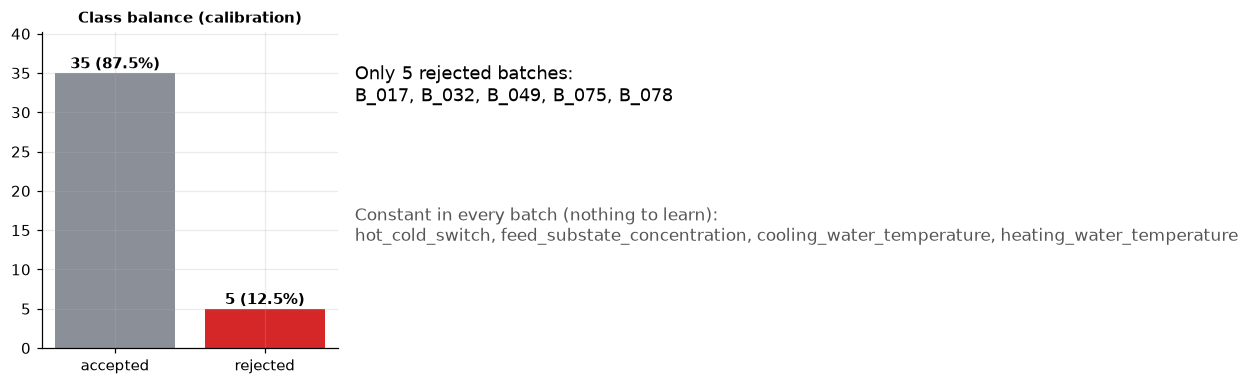

In [2]:
fig,ax=plt.subplots(1,2,figsize=(11,3.6),gridspec_kw=dict(width_ratios=[1,1.6]))
vc=y.value_counts(); ax[0].bar(vc.index,vc.values,color=[PAL[k] for k in vc.index])
for i,(k,v) in enumerate(vc.items()): ax[0].text(i,v+.6,f"{v} ({100*v/vc.sum():.1f}%)",ha="center",fontweight="bold")
ax[0].set_ylim(0,vc.max()*1.15); ax[0].set_title("Class balance (calibration)")
ax[1].axis("off"); ax[1].text(0,.9,"Only 5 rejected batches:\n"+", ".join(REJ_COL),fontsize=12,va="top"); ax[1].text(0,.45,f"Constant in every batch (nothing to learn):\n{', '.join(CONST)}",fontsize=11,va="top",color="#555")
plt.tight_layout(); plt.show()

## 2. Every variable over time
Grey band = middle 80 % of accepted batches, dark line = accepted median, each **rejected batch is its own colour** (only 5). Constant variables are left out.

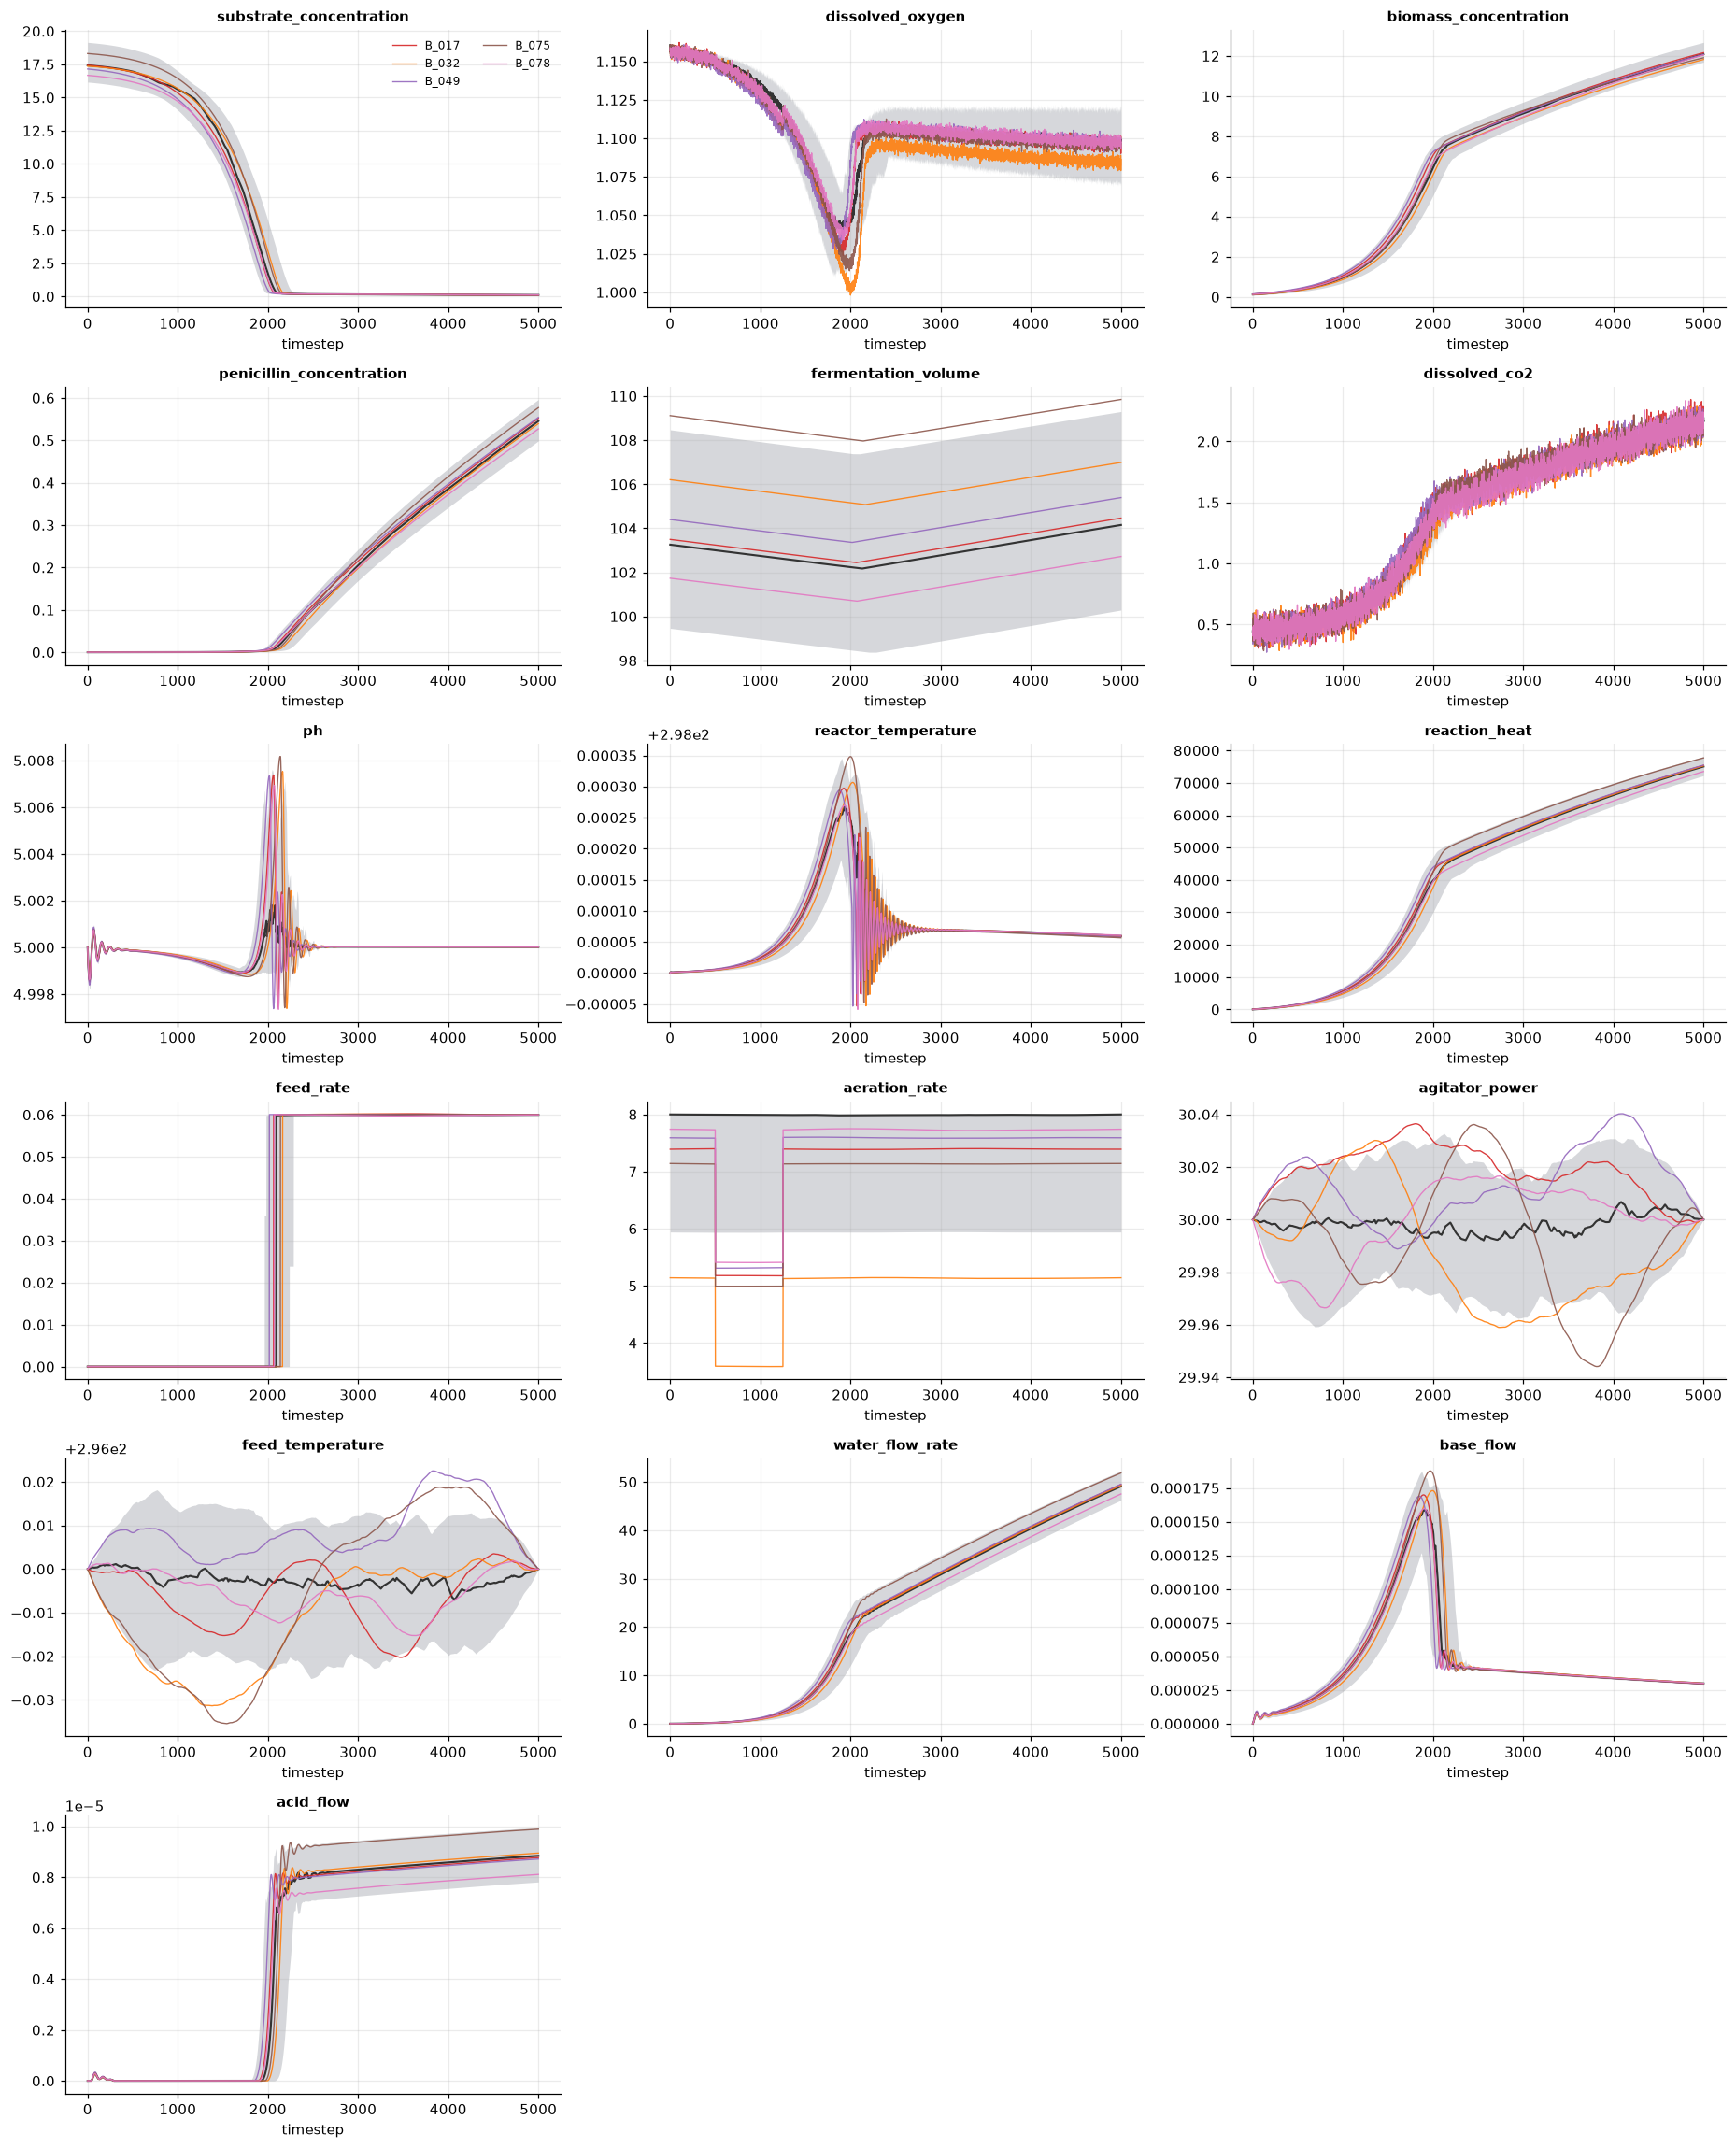

In [3]:
fig,axs=plt.subplots(6,3,figsize=(17,21))
for ax,v in zip(axs.ravel(),V):
    A=W[v].values; ax.fill_between(t,np.percentile(A[acc],10,axis=0),np.percentile(A[acc],90,axis=0),color=GREY,alpha=.35,lw=0)
    ax.plot(t,np.median(A[acc],0),color="#333",lw=1.4)
    for b,c in REJ_COL.items(): ax.plot(t,W[v].loc[b],color=c,lw=.9,alpha=.9,label=b)
    ax.set_title(v); ax.set_xlabel("timestep")
for ax in axs.ravel()[len(V):]: ax.axis("off")
axs[0,0].legend(fontsize=8,ncol=2); plt.tight_layout(); plt.show()

## 3. aeration_rate – the variable that gives the rejected batches away
In accepted batches the aeration rate is flat for the whole run (it varies only by ~0.03). In rejected batches it **drops and recovers** during the run, so the within-batch range (max − min) is 1.5–2.3.

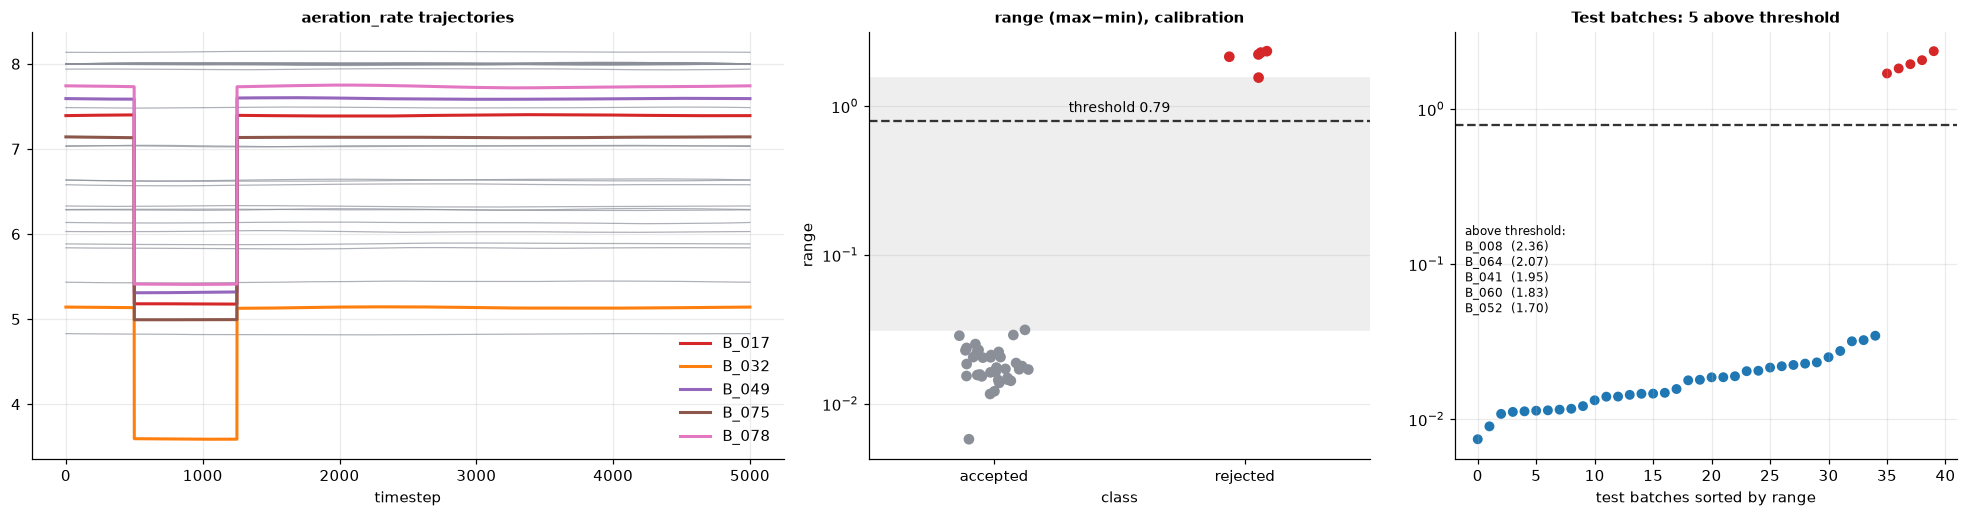

when does the drop happen? (rejected batches)
  B_017: drops from 7.39 to 5.18 between t=500 and t=1250
  B_032: drops from 5.14 to 3.59 between t=500 and t=1250
  B_049: drops from 7.59 to 5.31 between t=500 and t=1250
  B_075: drops from 7.14 to 4.99 between t=500 and t=1250
  B_078: drops from 7.74 to 5.41 between t=500 and t=1250


In [4]:
fig,ax=plt.subplots(1,3,figsize=(18,4.8),gridspec_kw=dict(width_ratios=[1.5,1,1]))
for b in ids:
    if y[b]=="accepted": ax[0].plot(t,W["aeration_rate"].loc[b],color=GREY,lw=.8,alpha=.7)
for b,c in REJ_COL.items(): ax[0].plot(t,W["aeration_rate"].loc[b],color=c,lw=2,label=b)
ax[0].legend(); ax[0].set_title("aeration_rate trajectories"); ax[0].set_xlabel("timestep")
r=rng["aeration_rate"]; d=pd.DataFrame({"range":r.values,"class":y.values})
sns.stripplot(data=d,x="class",y="range",hue="class",palette=PAL,order=["accepted","rejected"],ax=ax[1],size=7,jitter=.15,legend=False); ax[1].set_yscale("symlog",linthresh=.01)
ax[1].axhspan(r[acc].max(),r[rej].min(),color="#eee",zorder=0); ax[1].set_title("range (max−min), calibration"); 
thr=(r[acc].max()+r[rej].min())/2; ax[1].axhline(thr,color="#333",ls="--"); ax[1].text(.5,thr*1.15,f"threshold {thr:.2f}",ha="center",fontsize=9)
rt=rngT["aeration_rate"].sort_values(); ax[2].scatter(range(len(rt)),rt.values,c=[RED if x>thr else BLUE for x in rt],s=30); ax[2].set_yscale("symlog",linthresh=.01); ax[2].axhline(thr,color="#333",ls="--")
ax[2].set_title(f"Test batches: {int((rt>thr).sum())} above threshold"); ax[2].set_xlabel("test batches sorted by range")
ax[2].text(.02,.55,"above threshold:\n"+"\n".join(f"{b}  ({rt[b]:.2f})" for b in rt.index[rt>thr][::-1]),transform=ax[2].transAxes,fontsize=8,va="top")
plt.tight_layout(); plt.show()
print("when does the drop happen? (rejected batches)"); 
for b in REJ_COL:
    s=W["aeration_rate"].loc[b]; lo=s[s<s.iloc[0]-.5]; print(f"  {b}: {'no drop > 0.5' if lo.empty else f'drops from {s.iloc[0]:.2f} to {lo.min():.2f} between t={lo.index.min()} and t={lo.index.max()}'}")

## 4. Is aeration_rate unique? Separability of every variable by its within-batch range
AUC of the range feature (0.5 = no information, 1 = perfect). With 5 rejected batches, treat anything below ~0.9 with caution.

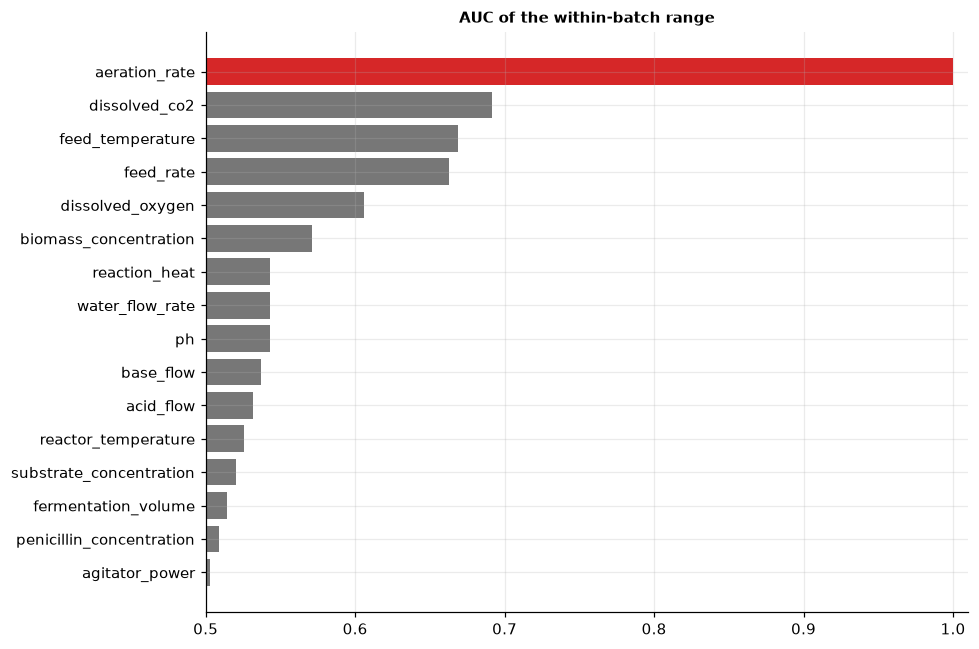

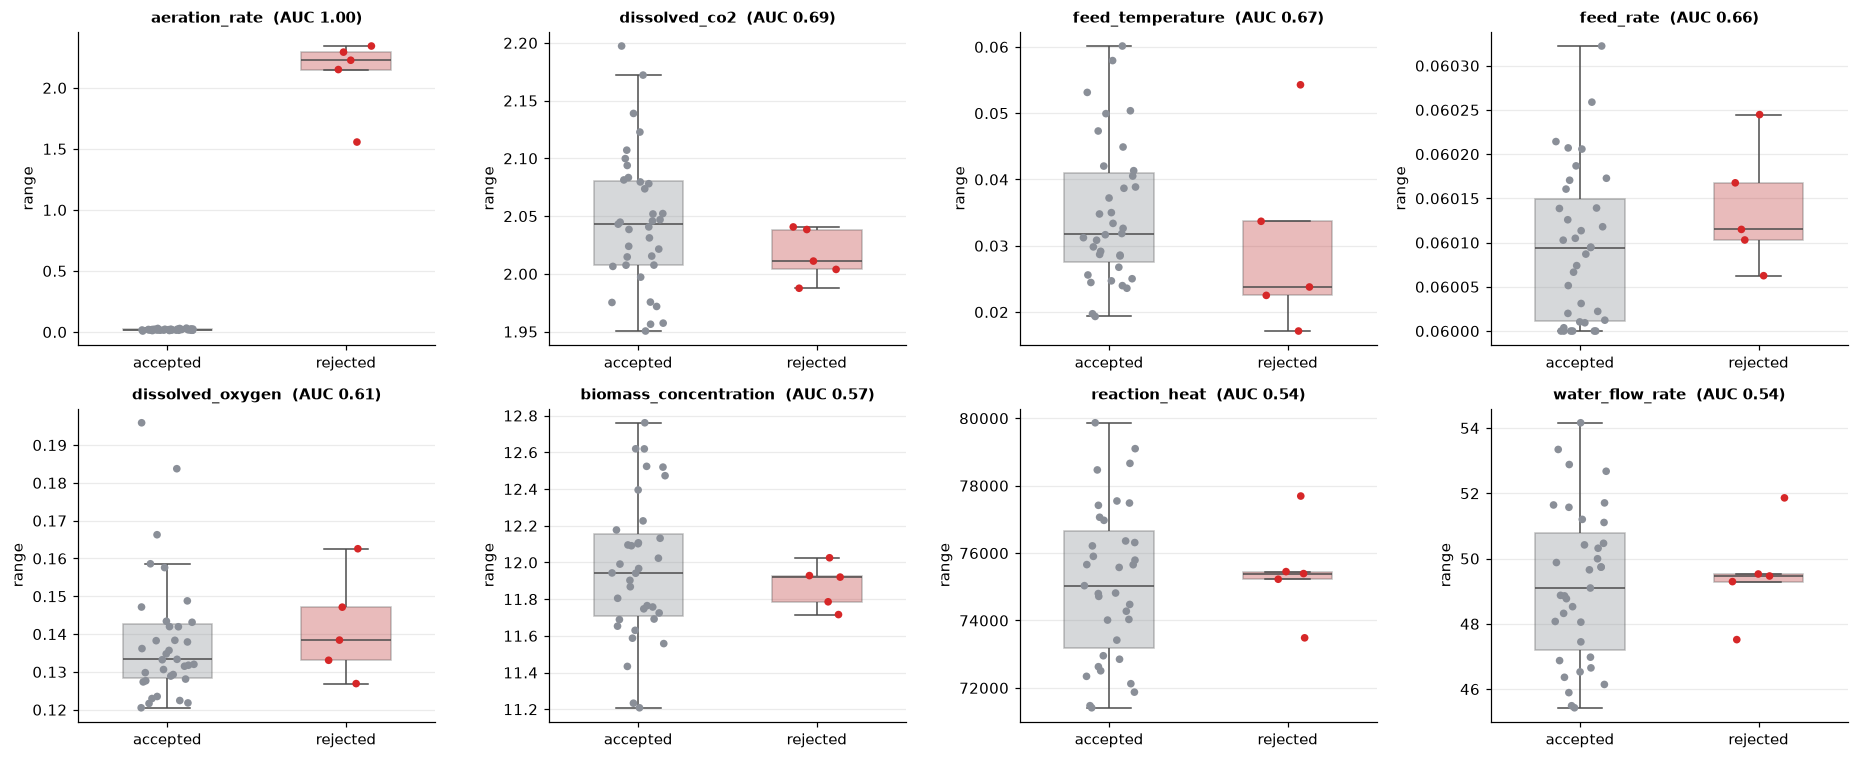

In [5]:
from sklearn.metrics import roc_auc_score
auc=pd.Series({v:roc_auc_score(rej,rng[v]) for v in V}); auc=((auc-.5).abs()+.5).sort_values()
fig,ax=plt.subplots(figsize=(9,6)); ax.barh(auc.index,auc.values,color=["#d62728" if v=="aeration_rate" else "#777" for v in auc.index]); ax.set_xlim(.5,1.01); ax.set_title("AUC of the within-batch range"); plt.tight_layout(); plt.show()
fig,axs=plt.subplots(2,4,figsize=(17,7))
for ax,v in zip(axs.ravel(),auc.index[::-1][:8]):
    d=pd.DataFrame({"x":rng[v].values,"class":y.values})
    sns.boxplot(data=d,x="class",y="x",hue="class",palette=PAL,order=["accepted","rejected"],ax=ax,width=.5,fliersize=0,boxprops=dict(alpha=.35),legend=False); sns.stripplot(data=d,x="class",y="x",hue="class",palette=PAL,order=["accepted","rejected"],ax=ax,size=5,jitter=.15,legend=False)
    ax.set_title(f"{v}  (AUC {auc[v]:.2f})"); ax.set_xlabel(""); ax.set_ylabel("range")
plt.tight_layout(); plt.show()

## 5. Phase alignment – batches run the same recipe at slightly different times
The feed turns on between t≈1900 and 2400. Aligning batches to that moment removes most of the visible spread.

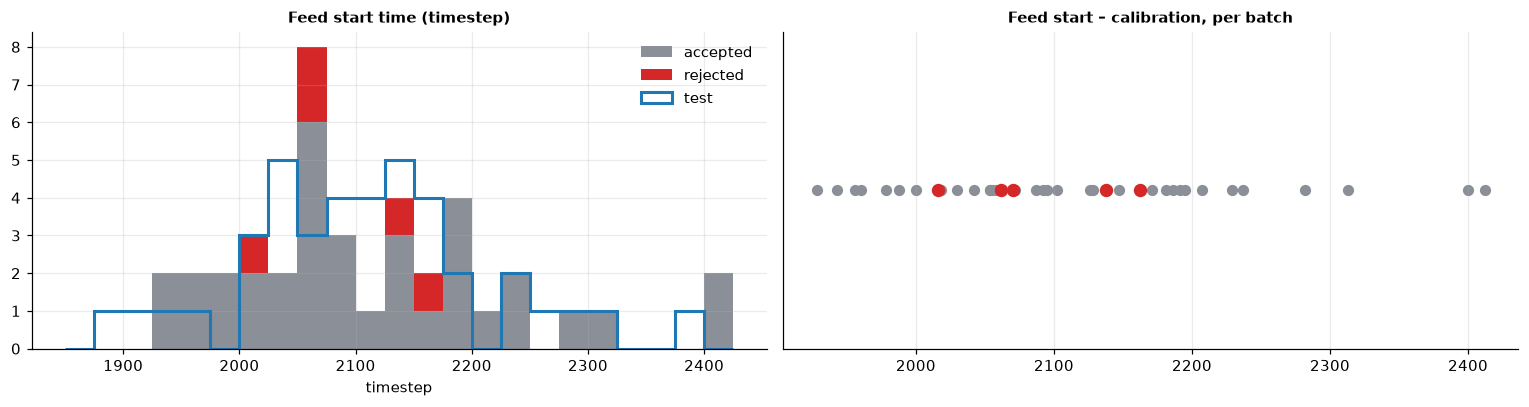

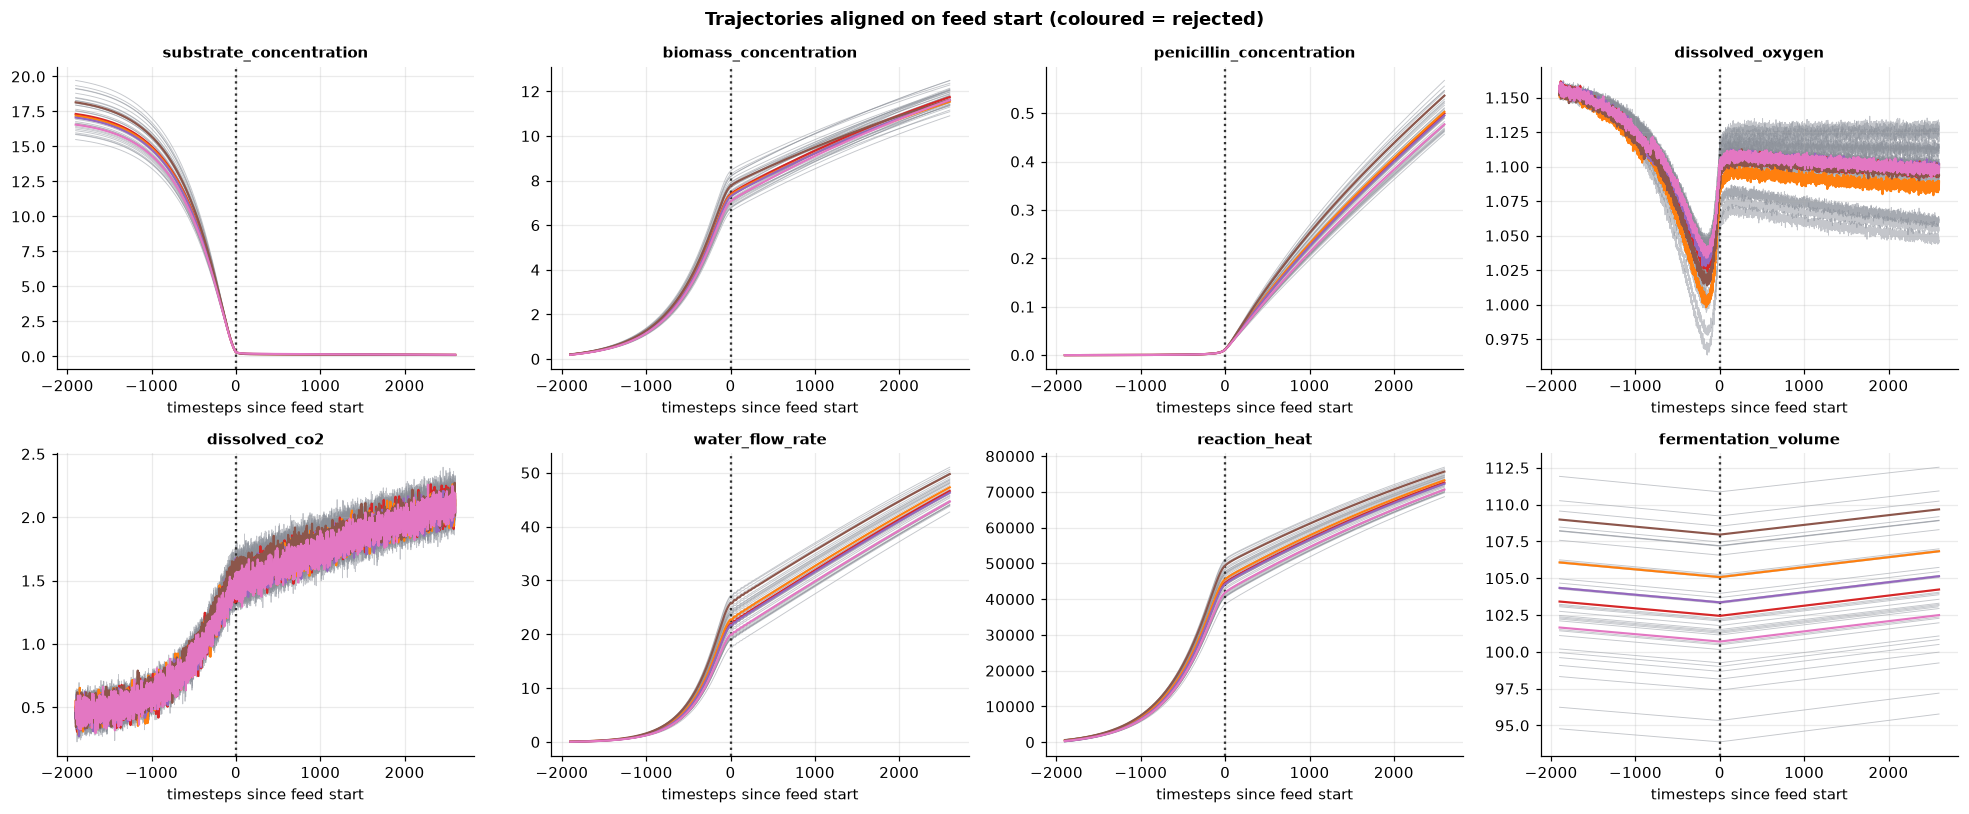

In [6]:
fs=pd.Series({b:int(W["feed_rate"].columns[(W["feed_rate"].loc[b]>.03).values][0]) for b in ids}); fst=pd.Series({b:int(WT["feed_rate"].columns[(WT["feed_rate"].loc[b]>.03).values][0]) for b in idt})
fig,ax=plt.subplots(1,2,figsize=(14,3.8))
ax[0].hist([fs[acc],fs[rej]],bins=np.arange(1850,2450,25),color=[GREY,RED],label=["accepted","rejected"],stacked=True); ax[0].hist(fst,bins=np.arange(1850,2450,25),histtype="step",color=BLUE,lw=2,label="test"); ax[0].legend(); ax[0].set_title("Feed start time (timestep)"); ax[0].set_xlabel("timestep")
ax[1].scatter(fs[acc],np.ones(acc.sum()),c=GREY,s=40); ax[1].scatter(fs[rej],np.ones(rej.sum()),c=RED,s=60); ax[1].set_yticks([]); ax[1].set_title("Feed start – calibration, per batch"); plt.tight_layout(); plt.show()
fig,axs=plt.subplots(2,4,figsize=(18,7.5)); lag=np.arange(-1900,2600)
for ax,v in zip(axs.ravel(),["substrate_concentration","biomass_concentration","penicillin_concentration","dissolved_oxygen","dissolved_co2","water_flow_rate","reaction_heat","fermentation_volume"]):
    for b in ids:
        s=W[v].loc[b].values; s0=fs[b]; x=np.arange(len(s))-s0; m=(x>=-1900)&(x<2600)
        ax.plot(x[m],s[m],color=REJ_COL.get(b,GREY),lw=1.4 if b in REJ_COL else .6,alpha=1 if b in REJ_COL else .5,zorder=3 if b in REJ_COL else 1)
    ax.axvline(0,color="#333",ls=":"); ax.set_title(v); ax.set_xlabel("timesteps since feed start")
plt.suptitle("Trajectories aligned on feed start (coloured = rejected)",fontweight="bold"); plt.tight_layout(); plt.show()

## 6. End-of-batch values and the dissolved-oxygen plateau
The yield (penicillin at the end) and the oxygen level after the growth phase.

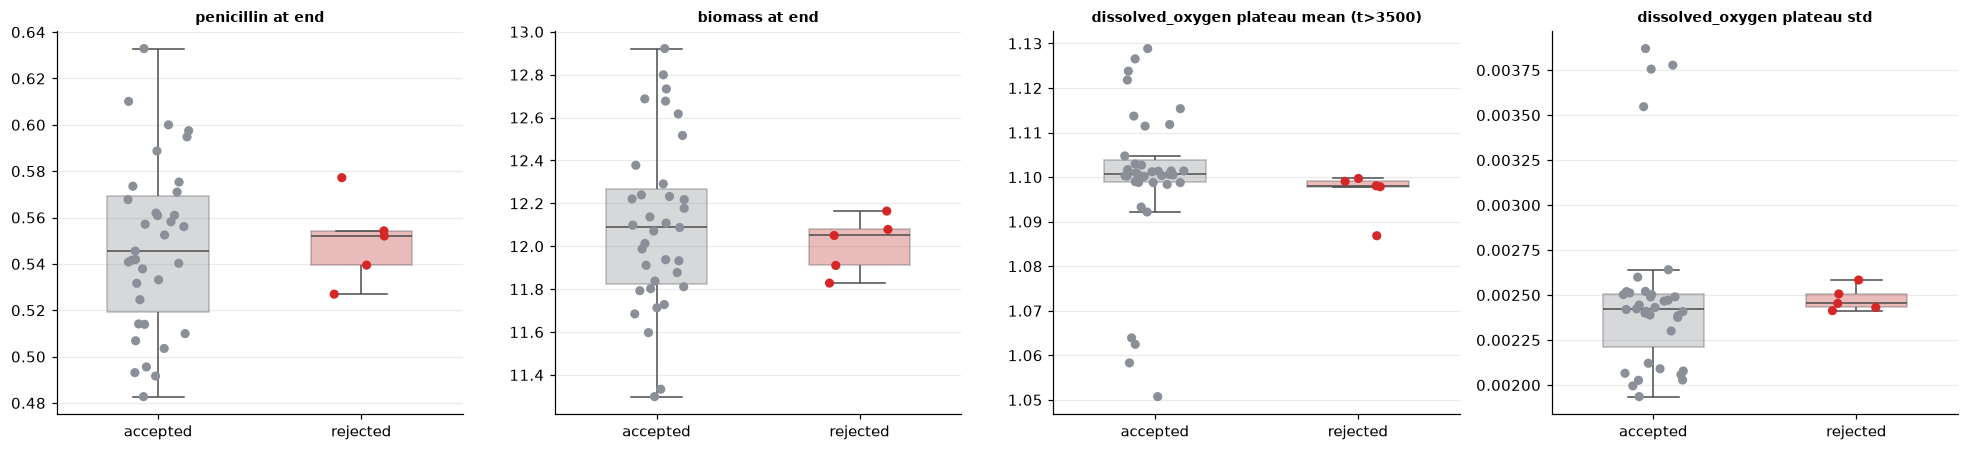

In [7]:
end=pd.DataFrame({v:W[v].iloc[:,-1] for v in V}); endT=pd.DataFrame({v:WT[v].iloc[:,-1] for v in V})
plat=pd.DataFrame({"do_plateau_mean":W["dissolved_oxygen"].loc[:,3500:].mean(axis=1),"do_plateau_std":W["dissolved_oxygen"].loc[:,3500:].std(axis=1)})
fig,axs=plt.subplots(1,4,figsize=(18,4.2))
for ax,(s,name) in zip(axs,[(end["penicillin_concentration"],"penicillin at end"),(end["biomass_concentration"],"biomass at end"),(plat.do_plateau_mean,"dissolved_oxygen plateau mean (t>3500)"),(plat.do_plateau_std,"dissolved_oxygen plateau std")]):
    d=pd.DataFrame({"x":s.values,"class":y.values}); sns.boxplot(data=d,x="class",y="x",hue="class",palette=PAL,order=["accepted","rejected"],ax=ax,width=.5,fliersize=0,boxprops=dict(alpha=.35),legend=False)
    sns.stripplot(data=d,x="class",y="x",hue="class",palette=PAL,order=["accepted","rejected"],ax=ax,size=6,jitter=.15,legend=False); ax.set_title(name,fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 7. Batches in feature space (PCA)
Per-batch features: mean, std, range and final value of every variable, robust-scaled and projected to 2D. Test batches are hollow blue.

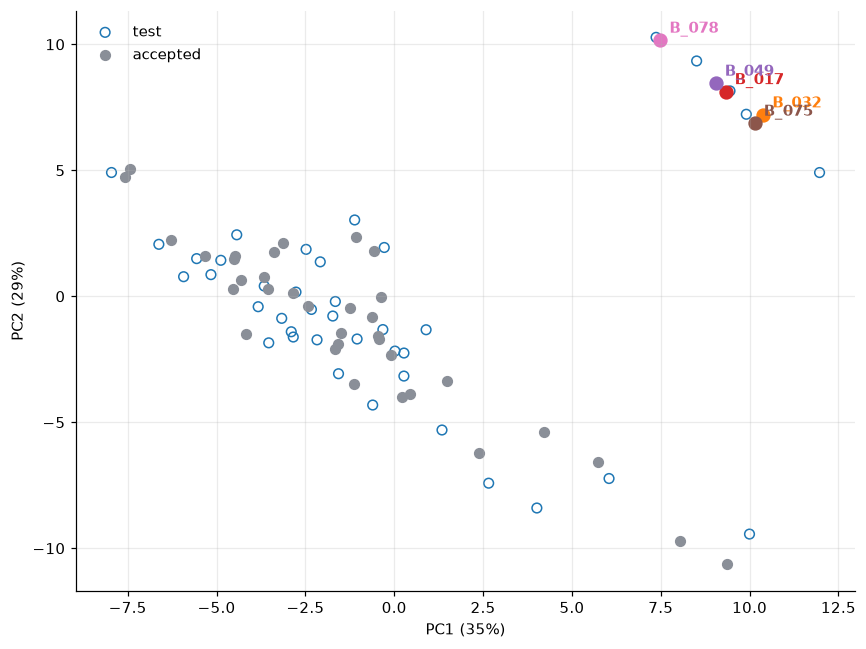

,PC1,PC2
aeration_rate_std,0.50,0.49
aeration_rate_range,0.50,0.49
dissolved_oxygen_last,-0.49,0.44
dissolved_oxygen_mean,-0.24,0.21
dissolved_oxygen_range,0.15,-0.15
dissolved_oxygen_std,0.13,-0.16


In [8]:
def feats(Wd): 
    return pd.concat([pd.DataFrame({v:Wd[v].mean(axis=1) for v in V}).add_suffix("_mean"),pd.DataFrame({v:Wd[v].std(axis=1) for v in V}).add_suffix("_std"),pd.DataFrame({v:Wd[v].max(axis=1)-Wd[v].min(axis=1) for v in V}).add_suffix("_range"),pd.DataFrame({v:Wd[v].iloc[:,-1] for v in V}).add_suffix("_last")],axis=1)
Fc=feats(W); Ft=feats(WT); keep=Fc.columns[Fc.std()>0]; Fc,Ft=Fc[keep],Ft[keep]
sc=RobustScaler().fit(Fc); Zc=np.clip(sc.transform(Fc),-10,10); Zt=np.clip(sc.transform(Ft),-10,10); pca=PCA(2).fit(Zc); Pc,Pt=pca.transform(Zc),pca.transform(Zt)
fig,ax=plt.subplots(figsize=(8,6)); ax.scatter(Pt[:,0],Pt[:,1],facecolors="none",edgecolors=BLUE,s=40,label="test"); ax.scatter(Pc[acc,0],Pc[acc,1],c=GREY,s=40,label="accepted")
for b,c in REJ_COL.items(): k=ids.index(b); ax.scatter(*Pc[k],c=c,s=70); ax.annotate(b,Pc[k],xytext=(6,5),textcoords="offset points",color=c,fontweight="bold")
ax.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f}%)"); ax.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f}%)"); ax.legend(); plt.tight_layout(); plt.show()
load=pd.DataFrame(pca.components_.T,index=Fc.columns,columns=["PC1","PC2"]); display(load.reindex(load.PC1.abs().sort_values(ascending=False).index).head(6).round(2))

## 8. Relationships between variables

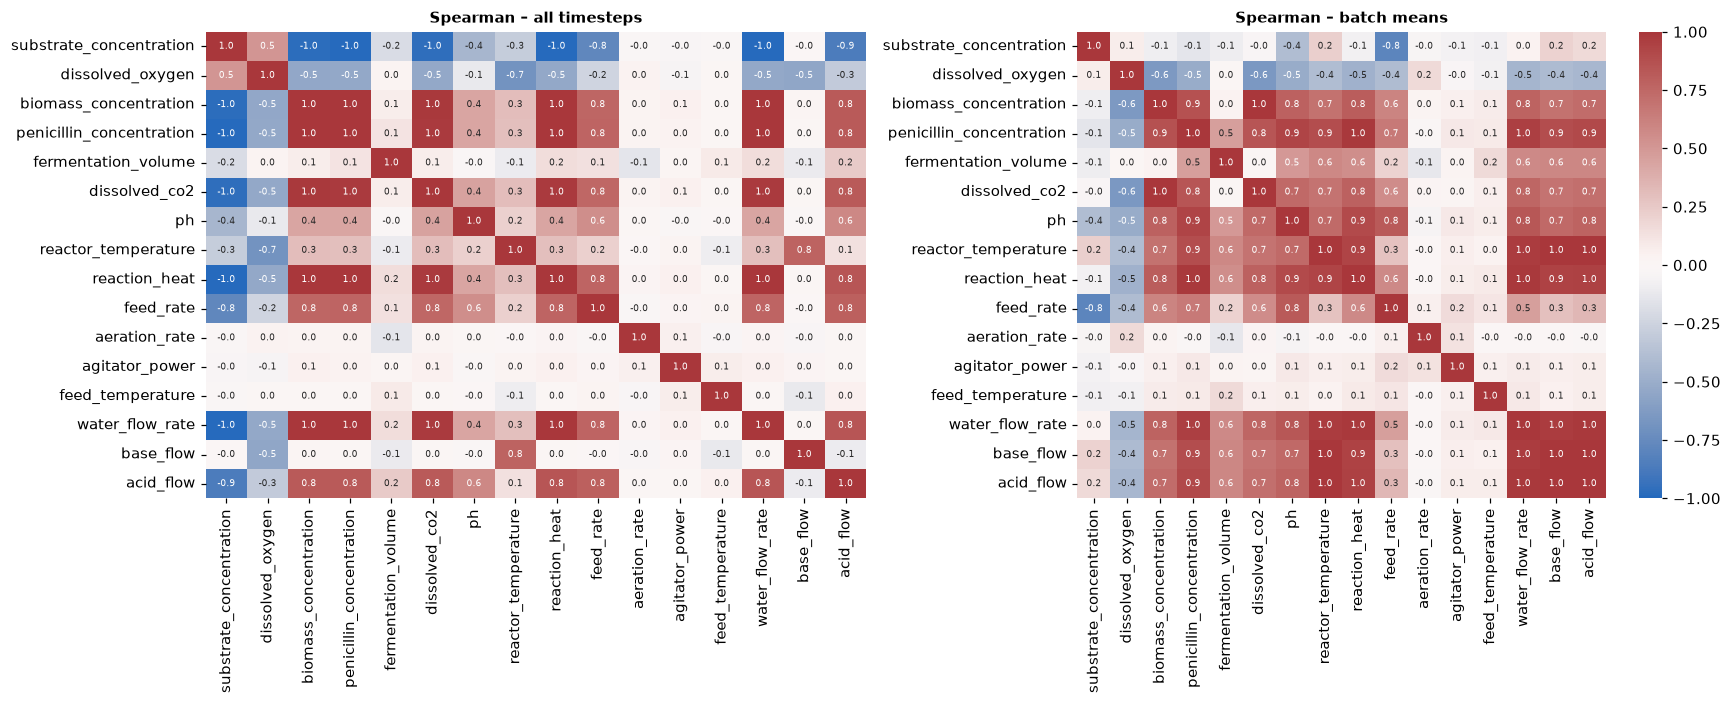

In [9]:
m=pd.DataFrame({v:W[v].mean(axis=1) for v in V}); 
fig,ax=plt.subplots(1,2,figsize=(16,6.5)); sns.heatmap(cal[V].sample(50000,random_state=0).corr("spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,ax=ax[0],annot=True,fmt=".1f",annot_kws=dict(size=6),cbar=False); ax[0].set_title("Spearman – all timesteps"); ax[0].grid(False)
sns.heatmap(m.corr("spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,ax=ax[1],annot=True,fmt=".1f",annot_kws=dict(size=6)); ax[1].set_title("Spearman – batch means"); ax[1].grid(False); plt.tight_layout(); plt.show()

## 9. Calibration vs test

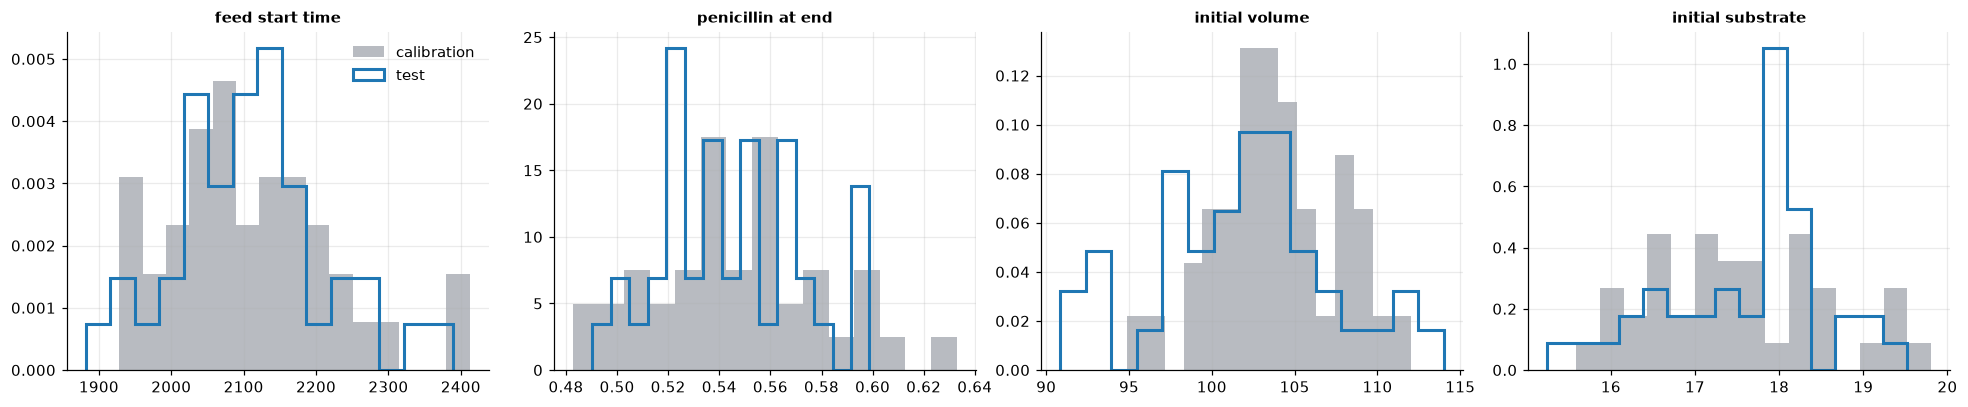

In [10]:
cmp=pd.DataFrame({"feed start":pd.concat([fs.rename("cal"),fst.rename("test")],axis=1).describe().T.stack()}) if False else None
fig,axs=plt.subplots(1,4,figsize=(18,3.8))
for ax,(a,b,name) in zip(axs,[(fs,fst,"feed start time"),(end["penicillin_concentration"],endT["penicillin_concentration"],"penicillin at end"),(W["fermentation_volume"].iloc[:,0],WT["fermentation_volume"].iloc[:,0],"initial volume"),(W["substrate_concentration"].iloc[:,0],WT["substrate_concentration"].iloc[:,0],"initial substrate")]):
    ax.hist(a,bins=15,alpha=.6,color=GREY,density=True,label="calibration"); ax.hist(b,bins=15,histtype="step",color=BLUE,lw=2,density=True,label="test"); ax.set_title(name)
axs[0].legend(); plt.tight_layout(); plt.show()

## 10. Does the aeration drop (t = 500–1250) leave a mark on other variables?
For every variable and timestep, a batch's **z-score = (value − median of accepted batches) / std of accepted batches**. Rejected batches are compared with all 35 accepted ones; each accepted batch is compared with the *other* 34 (leave-one-out), so we know how large a deviation is normal for a batch that is fine. Because batches already differ before the window, the quantity that matters is the **change in z between the pre-window baseline (t = 1–499) and the window (t = 500–1250)**. Variables that are exactly zero for every batch in the window (`feed_rate`, `acid_flow`) have no spread and are skipped.

In [11]:
WIN=(500,1250); PRE=(1,499); AFTER=(1251,1700)
Vz=[v for v in V if W[v].loc[:,WIN[0]:WIN[1]].std().max()>0]   # variables with any spread inside the window
accb=[b for b in ids if y[b]=="accepted"]; rejb=list(REJ_COL)
def zts(v,b,ref):
    R=W[v].loc[ref]; return (W[v].loc[b]-R.median())/R.std().replace(0,np.nan)
Z={v:pd.concat([zts(v,b,accb if b in rejb else [a for a in accb if a!=b]).rename(b) for b in ids],axis=1).T for v in Vz}
mz=lambda z,a,b: z.loc[:,a:b].mean(axis=1)
chg={v:mz(Z[v],*WIN)-mz(Z[v],*PRE) for v in Vz}          # change in z: window minus pre-window baseline
aft={v:mz(Z[v],*AFTER)-mz(Z[v],*PRE) for v in Vz}
rows=[]
for v in Vz:
    c=chg[v]; a=c[accb].abs(); r=c[rejb]
    rows.append(dict(variable=v,rej_mean_change=r.mean(),rej_all_same_sign=bool((r>0).all() or (r<0).all()),rej_max_abs=r.abs().max(),acc_LOO_p95_abs=a.quantile(.95),acc_LOO_max_abs=a.max(),
                     rej_beyond_every_accepted=int((r.abs()>a.max()).sum()),rej_after_window_mean_change=aft[v][rejb].mean()))
T=pd.DataFrame(rows).set_index("variable").sort_values("rej_max_abs",ascending=False)
display(T.style.format({c:"{:.2f}" for c in T.columns if T[c].dtype==float}).background_gradient(subset=["rej_max_abs"],cmap="Reds"))

,rej_mean_change,rej_all_same_sign,rej_max_abs,acc_LOO_p95_abs,acc_LOO_max_abs,rej_beyond_every_accepted,rej_after_window_mean_change
variable,,,,,,,
aeration_rate,-2.18,True,2.42,0.01,0.01,5,0.01
agitator_power,-0.08,False,1.05,1.00,1.49,0,-0.09
dissolved_oxygen,-0.76,True,0.93,0.61,0.81,2,-0.09
feed_temperature,-0.13,True,0.29,0.88,1.26,0,-0.58
ph,0.03,False,0.27,0.91,1.07,0,-0.04
substrate_concentration,-0.09,False,0.26,0.54,0.71,0,-0.17
dissolved_co2,0.01,False,0.21,0.57,0.65,0,0.01
base_flow,-0.02,True,0.03,0.03,0.03,0,-0.01
water_flow_rate,0.00,False,0.01,0.08,0.09,0,0.01


### 10.1 Change in z during the drop, per rejected batch
Left: red/blue = the variable moved up/down (in accepted-spread units) during the drop relative to the batch's own baseline. Right: size of that change for rejected batches (coloured dots) vs. what accepted batches show by chance (grey bar = 95th percentile, tick = maximum).

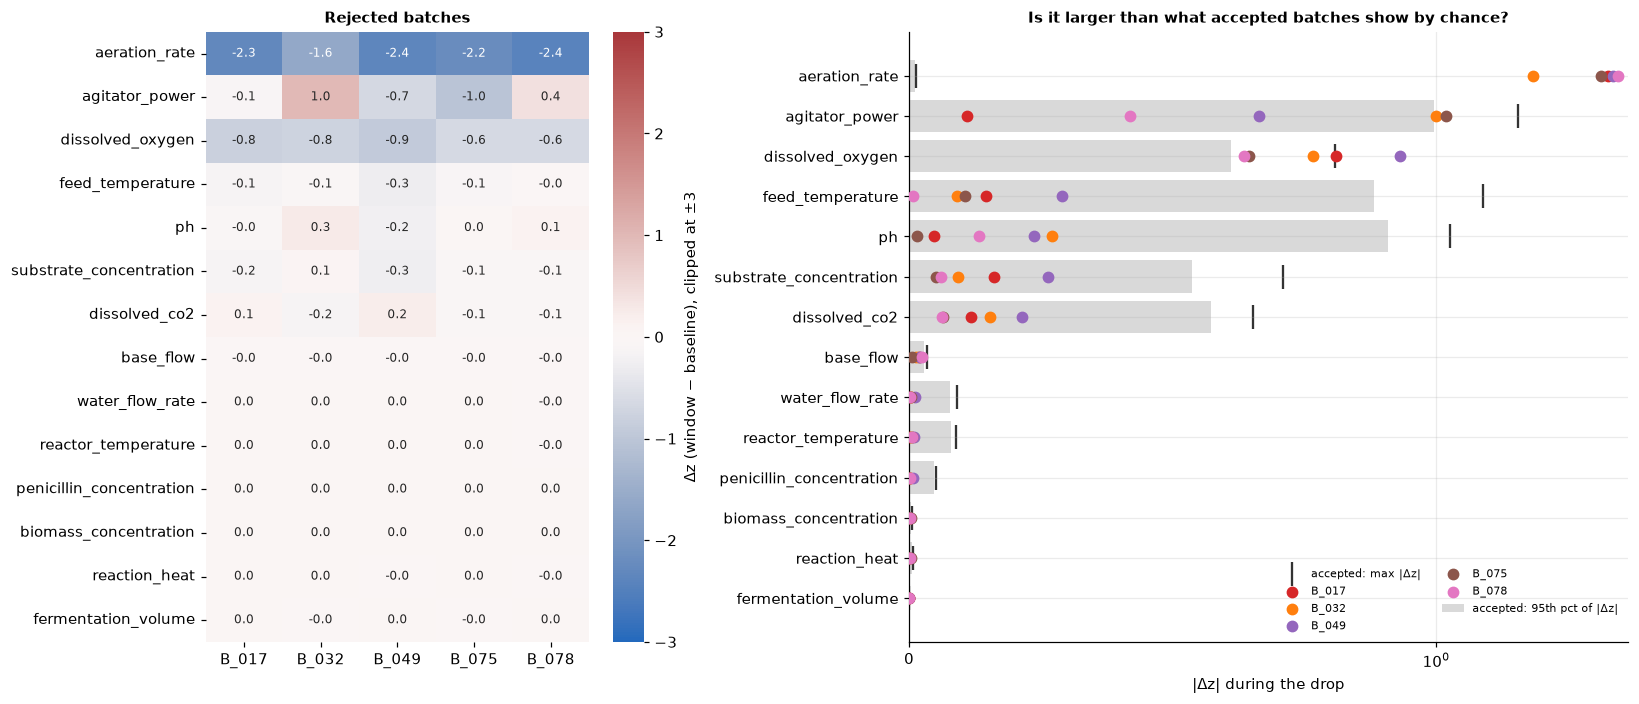

In [12]:
order=list(T.index); H=pd.DataFrame({b:[chg[v][b] for v in order] for b in rejb},index=order)
fig,ax=plt.subplots(1,2,figsize=(15,6.5),gridspec_kw=dict(width_ratios=[1,1.5]))
sns.heatmap(H,cmap="vlag",center=0,vmin=-3,vmax=3,annot=True,fmt=".1f",annot_kws=dict(size=8),ax=ax[0],cbar_kws=dict(label="Δz (window − baseline), clipped at ±3")); ax[0].grid(False); ax[0].set_title("Rejected batches"); ax[0].set_ylabel("")
y_=np.arange(len(order))[::-1]
ax[1].barh(y_,T.acc_LOO_p95_abs,color="#d9d9d9",label="accepted: 95th pct of |Δz|"); ax[1].scatter(T.acc_LOO_max_abs,y_,marker="|",s=250,color="#333",label="accepted: max |Δz|")
for b,c in REJ_COL.items(): ax[1].scatter(H[b].abs(),y_,color=c,s=45,zorder=5,label=b)
ax[1].set_yticks(y_,order); ax[1].set_xscale("symlog",linthresh=1); ax[1].set_xlabel("|Δz| during the drop"); ax[1].legend(fontsize=7,ncol=2,loc="lower right"); ax[1].set_title("Is it larger than what accepted batches show by chance?")
plt.tight_layout(); plt.show()

### 10.2 z-score of every variable over time
Grey lines = accepted batches (vs. the others), coloured = rejected, shaded = the aeration-drop window. Curves are smoothed (25-step moving average) so level shifts are visible through the noise.

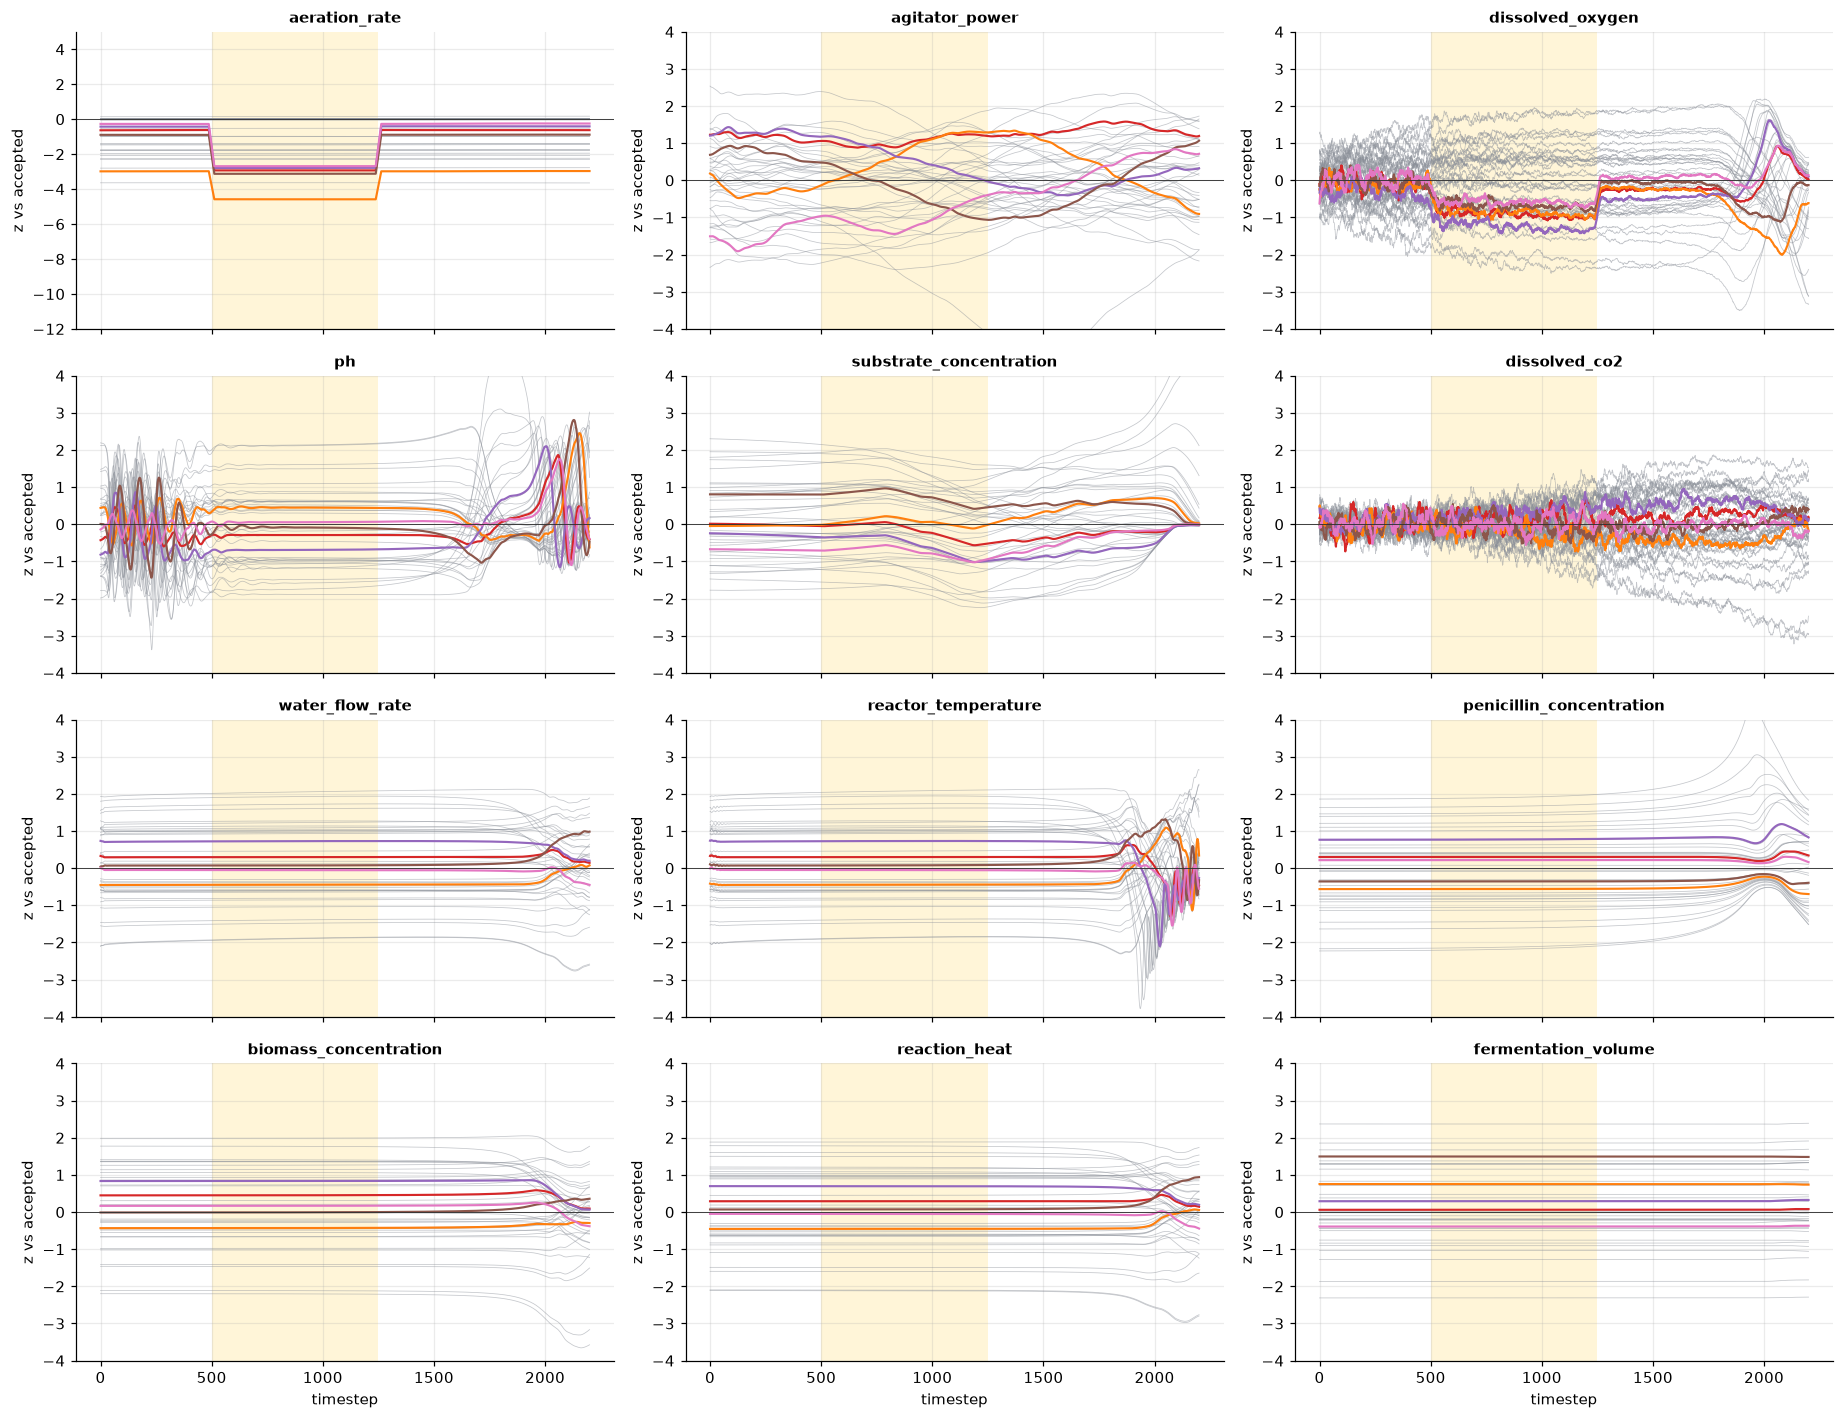

In [13]:
show=[v for v in order if v in("aeration_rate","dissolved_oxygen","biomass_concentration","dissolved_co2","substrate_concentration","penicillin_concentration","ph","reactor_temperature","reaction_heat","water_flow_rate","fermentation_volume","agitator_power")]
fig,axs=plt.subplots(4,3,figsize=(17,13),sharex=True)
for ax,v in zip(axs.ravel(),show):
    sm_=Z[v].T.rolling(25,center=True,min_periods=1).mean().T.loc[:,:2200]
    for b in accb: ax.plot(sm_.columns,sm_.loc[b],color=GREY,lw=.5,alpha=.5)
    for b,c in REJ_COL.items(): ax.plot(sm_.columns,sm_.loc[b],color=c,lw=1.4)
    ax.axvspan(*WIN,color="#ffd966",alpha=.25,lw=0); ax.axhline(0,color="#333",lw=.6); ax.set_title(v); ax.set_ylim(-4,4) if v!="aeration_rate" else ax.set_ylim(-12,5)
    ax.set_ylabel("z vs accepted")
for ax in axs[-1]: ax.set_xlabel("timestep")
plt.tight_layout(); plt.show()

### 10.3 The same thing in raw units for the variables you asked about
Accepted median ± 2 std (grey), rejected batches in colour; yellow = drop window.

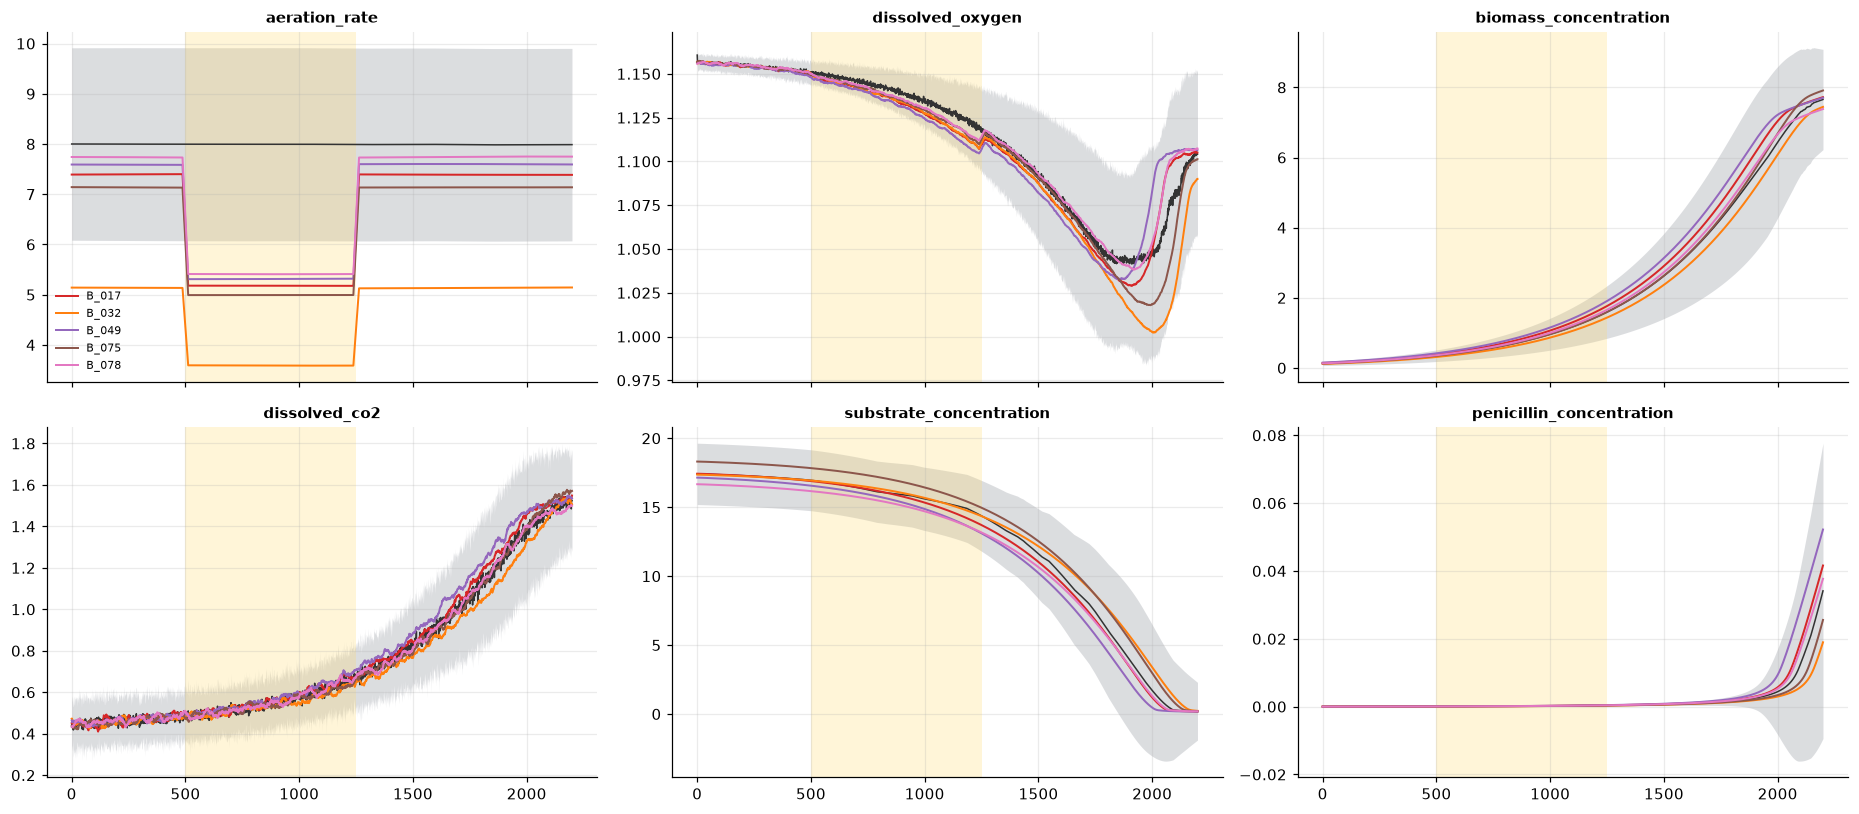

,DO mean in window,accepted std (batch means)
accepted median,1.1378,0.0061
B_017,1.1322,0.0061
B_032,1.1325,0.0061
B_049,1.1301,0.0061
B_075,1.1338,0.0061
B_078,1.1344,0.0061


DO – step-to-step noise inside window (std of first difference):
  rejected 0.00267–0.00290 | accepted 0.00262–0.00299 (median 0.00280)


In [14]:
fig,axs=plt.subplots(2,3,figsize=(17,7.5),sharex=True)
for ax,v in zip(axs.ravel(),["aeration_rate","dissolved_oxygen","biomass_concentration","dissolved_co2","substrate_concentration","penicillin_concentration"]):
    A=W[v].loc[accb]; m,s=A.median(),A.std(); sl=slice(0,2200)
    ax.fill_between(m.index[sl],(m-2*s)[sl],(m+2*s)[sl],color=GREY,alpha=.3,lw=0); ax.plot(m.index[sl],m[sl],color="#333",lw=1)
    for b,c in REJ_COL.items(): ax.plot(W[v].columns[sl],W[v].loc[b].rolling(25,center=True,min_periods=1).mean()[sl],color=c,lw=1.3,label=b)
    ax.axvspan(*WIN,color="#ffd966",alpha=.25,lw=0); ax.set_title(v)
axs[0,0].legend(fontsize=7); plt.tight_layout(); plt.show()
dd=pd.DataFrame({"accepted median":W["dissolved_oxygen"].loc[accb,WIN[0]:WIN[1]].mean(axis=1).median(),**{b:W["dissolved_oxygen"].loc[b,WIN[0]:WIN[1]].mean() for b in rejb}},index=["DO mean in window"]).T
dd["accepted std (batch means)"]=W["dissolved_oxygen"].loc[accb,WIN[0]:WIN[1]].mean(axis=1).std(); display(dd.round(4))
nz=pd.DataFrame({v:{**{"rejected mean |Δz| over 5":chg[v][rejb].abs().mean()}} for v in ["dissolved_oxygen","biomass_concentration"]}).T; print("DO – step-to-step noise inside window (std of first difference):")
sn=W["dissolved_oxygen"].loc[:,WIN[0]:WIN[1]].diff(axis=1).std(axis=1); print(f"  rejected {sn[rejb].min():.5f}–{sn[rejb].max():.5f} | accepted {sn[accb].min():.5f}–{sn[accb].max():.5f} (median {sn[accb].median():.5f})")

## 11. Initial values (t = 0): calibration vs test
Is every test batch *starting* inside the range covered by the calibration batches? For each variable the calibration range is the min–max of its t = 0 value over the 40 calibration batches. Variables that are identical in all batches at t = 0 cannot be out of range and are listed as constant.

In [15]:
c0=cal.groupby("batch_id").first()[ALL]; t0=test.groupby("batch_id").first()[ALL]
S=pd.DataFrame({"cal_min":c0.min(),"cal_max":c0.max(),"cal_std":c0.std(),"test_min":t0.min(),"test_max":t0.max()})
S["test_out_of_range"]=[int(((t0[v]<c0[v].min())|(t0[v]>c0[v].max())).sum()) for v in ALL]
const0=[v for v in ALL if c0[v].nunique()==1 and t0[v].nunique()==1 and c0[v].iloc[0]==t0[v].iloc[0]]
print("identical in every batch at t=0 (calibration and test):",const0)
display(S.drop(index=const0).style.format({k:"{:.5g}" for k in ["cal_min","cal_max","cal_std","test_min","test_max"]}).background_gradient(subset=["test_out_of_range"],cmap="Reds"))
rows=[]
for v in S.index.difference(const0):
    lo,hi,sd=c0[v].min(),c0[v].max(),c0[v].std()
    for b,x in t0[v].items():
        if x<lo or x>hi:
            ex=lo-x if x<lo else x-hi; rows.append(dict(batch=b,variable=v,test_value=x,side="below" if x<lo else "above",cal_min=lo,cal_max=hi,excess=ex,excess_pct_of_cal_range=100*ex/(hi-lo),excess_in_cal_std=ex/sd))
OUT=pd.DataFrame(rows).sort_values(["batch","excess_pct_of_cal_range"],ascending=[True,False]).reset_index(drop=True)
print(f"{len(OUT)} out-of-range values in {OUT.batch.nunique()} of {len(t0)} test batches")
display(OUT.style.format({"test_value":"{:.5g}","cal_min":"{:.5g}","cal_max":"{:.5g}","excess":"{:.4g}","excess_pct_of_cal_range":"{:.1f}","excess_in_cal_std":"{:.2f}"}).background_gradient(subset=["excess_pct_of_cal_range"],cmap="Reds"))

identical in every batch at t=0 (calibration and test): ['penicillin_concentration', 'ph', 'reactor_temperature', 'reaction_heat', 'feed_rate', 'agitator_power', 'feed_temperature', 'water_flow_rate', 'hot_cold_switch', 'base_flow', 'acid_flow', 'feed_substate_concentration', 'cooling_water_temperature', 'heating_water_temperature']


,cal_min,cal_max,cal_std,test_min,test_max,test_out_of_range
substrate_concentration,15.589,19.803,1.0584,15.243,19.519,2
dissolved_oxygen,1.156,1.164,0.0020112,1.1567,1.1655,2
biomass_concentration,0.065669,0.18069,0.0282,0.07677,0.19347,1
fermentation_volume,94.864,112,3.7837,90.838,114,7
dissolved_co2,0.30998,0.56113,0.060014,0.36703,0.63083,3
aeration_rate,4.8289,8.1353,0.96126,4.3289,8.8353,5


20 out-of-range values in 18 of 40 test batches


,batch,variable,test_value,side,cal_min,cal_max,excess,excess_pct_of_cal_range,excess_in_cal_std
0,B_002,dissolved_co2,0.63083,above,0.30998,0.56113,0.0697,27.8,1.16
1,B_002,aeration_rate,8.8353,above,4.8289,8.1353,0.7,21.2,0.73
2,B_007,fermentation_volume,92.294,below,94.864,112,2.57,15.0,0.68
3,B_008,fermentation_volume,92.694,below,94.864,112,2.171,12.7,0.57
4,B_026,fermentation_volume,93.879,below,94.864,112,0.9854,5.8,0.26
5,B_029,fermentation_volume,114,above,94.864,112,2.001,11.7,0.53
6,B_030,aeration_rate,4.3289,below,4.8289,8.1353,0.5,15.1,0.52
7,B_030,fermentation_volume,112.42,above,94.864,112,0.4144,2.4,0.11
8,B_036,fermentation_volume,90.838,below,94.864,112,4.026,23.5,1.06
9,B_040,fermentation_volume,92.439,below,94.864,112,2.425,14.2,0.64


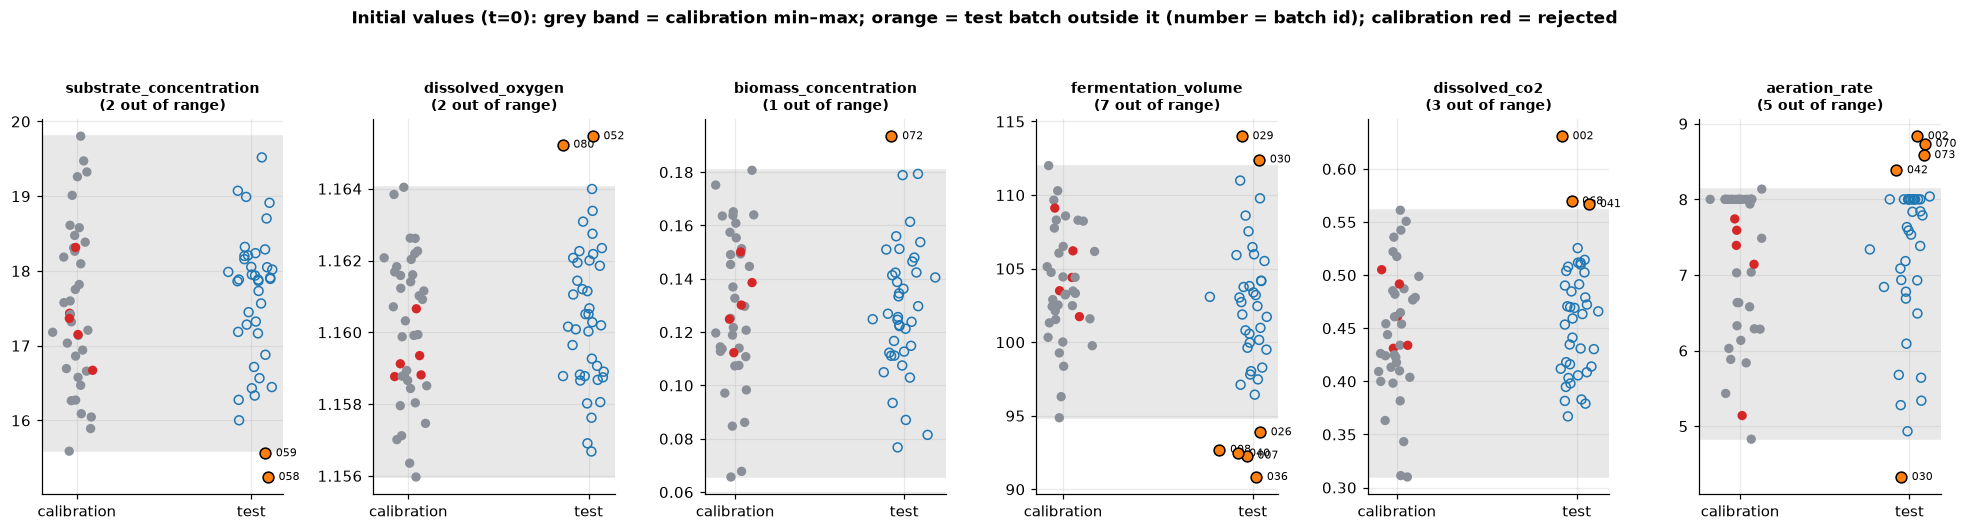

In [16]:
vv=[v for v in ALL if v not in const0]; fig,axs=plt.subplots(1,len(vv),figsize=(3*len(vv),4.6))
rng_=np.random.default_rng(0)
for ax,v in zip(axs,vv):
    lo,hi=c0[v].min(),c0[v].max(); ax.axhspan(lo,hi,color="#e8e8e8",zorder=0)
    ax.scatter(rng_.normal(0,.06,len(c0)),c0[v],c=[RED if y[b]=="rejected" else GREY for b in c0.index],s=26,zorder=3)
    out=(t0[v]<lo)|(t0[v]>hi); xs=1+rng_.normal(0,.06,len(t0))
    ax.scatter(xs[~out.values],t0[v][~out],facecolors="none",edgecolors=BLUE,s=34,zorder=3)
    ax.scatter(xs[out.values],t0[v][out],c="#ff7f0e",edgecolors="k",s=50,zorder=4)
    for xx,(b,val) in zip(xs[out.values],t0[v][out].items()): ax.annotate(b[2:],(xx,val),xytext=(7,-2),textcoords="offset points",fontsize=7)
    ax.set_xticks([0,1],["calibration","test"]); ax.set_title(f"{v}\n({int(out.sum())} out of range)",fontsize=9)
plt.suptitle("Initial values (t=0): grey band = calibration min–max; orange = test batch outside it (number = batch id); calibration red = rejected",y=1.04,fontsize=11,fontweight="bold"); plt.tight_layout(); plt.show()

**Reading it:** 14 of the 20 variables are identical in every batch at t = 0, so only six can be out of range: `substrate_concentration`, `dissolved_oxygen`, `biomass_concentration`, `fermentation_volume`, `dissolved_co2` and `aeration_rate`. `fermentation_volume` (7 test batches) and `aeration_rate` (5) account for most cases. Excesses are mostly small (a few % of the calibration range, below one calibration std); the largest are `B_002` `dissolved_co2` (28 % of the range) and `B_036` `fermentation_volume` (23 %). With only 40 calibration batches, a test batch falling slightly outside the observed min–max is expected for a few variables.